# Model Explainability & Early-Warning Framework

**Project:** Predicting Performance Trajectories of Women Micro-Enterprises: An Early Warning Framework

This notebook converts the final modelling result into an **interpretable early-warning decision-support prototype**.


In [1]:
# 0. Setup

from google.colab import drive
from pathlib import Path

import json
import math
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
from sklearn.utils.class_weight import compute_sample_weight

import joblib

warnings.filterwarnings("ignore")

drive.mount("/content/drive")

project_candidates = [
    Path(
        "/content/drive/MyDrive/24088950_MAI_Research"
    ),
    Path(
        "/content/drive/MyDrive/24088950 MAI Research"
    )
]

PROJECT_DIR = None

for candidate in project_candidates:

    expected = (
        candidate
        / "outputs"
        / "final_modelling_dataset_primary.csv"
    )

    if expected.exists():

        PROJECT_DIR = candidate
        break

if PROJECT_DIR is None:

    raise FileNotFoundError(
        "The research project folder could not be located. "
        "Check the MyDrive project-folder name."
    )

OUTPUT_DIR = PROJECT_DIR / "outputs"

MODEL_RESULTS_DIR = (
    OUTPUT_DIR
    / "model_results"
)

DEPLOYMENT_DIR = (
    OUTPUT_DIR
    / "deployment"
)

DEPLOYMENT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PRIMARY_PATH = (
    OUTPUT_DIR
    / "final_modelling_dataset_primary.csv"
)

FEATURE_MANIFEST_PATH = (
    OUTPUT_DIR
    / "model_feature_manifest.csv"
)

MODEL_COMPARISON_PATH = (
    MODEL_RESULTS_DIR
    / "primary_model_comparison.csv"
)

FOLD_RESULTS_PATH = (
    MODEL_RESULTS_DIR
    / "primary_nested_cv_fold_results.csv"
)

OOF_PATH = (
    MODEL_RESULTS_DIR
    / "primary_out_of_fold_predictions.csv"
)

BEST_PARAMS_PATH = (
    MODEL_RESULTS_DIR
    / "final_best_parameters.json"
)

print("Project folder:", PROJECT_DIR)
print("Deployment folder:", DEPLOYMENT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/24088950_MAI_Research
Deployment folder: /content/drive/MyDrive/24088950_MAI_Research/outputs/deployment


## 1. Load Final Modelling and Evaluation Outputs

In [2]:
# 1. Load Notebook 04 and Notebook 05 outputs

required_paths = [
    PRIMARY_PATH,
    MODEL_COMPARISON_PATH,
    OOF_PATH,
    BEST_PARAMS_PATH
]

missing_paths = [
    path
    for path in required_paths
    if not path.exists()
]

if missing_paths:

    raise FileNotFoundError(
        "Missing required outputs:\n"
        + "\n".join(
            str(path)
            for path in missing_paths
        )
    )

primary_df = pd.read_csv(
    PRIMARY_PATH
)

model_comparison = pd.read_csv(
    MODEL_COMPARISON_PATH
)

oof_predictions = pd.read_csv(
    OOF_PATH
)

with open(
    BEST_PARAMS_PATH,
    "r"
) as file:

    final_best_params = json.load(
        file
    )

feature_manifest = (
    pd.read_csv(
        FEATURE_MANIFEST_PATH
    )
    if FEATURE_MANIFEST_PATH.exists()
    else pd.DataFrame()
)

fold_results = (
    pd.read_csv(
        FOLD_RESULTS_PATH
    )
    if FOLD_RESULTS_PATH.exists()
    else pd.DataFrame()
)

TARGET_COLUMN = (
    "Performance Trajectory"
)

print(
    "Primary dataset shape:",
    primary_df.shape
)

display(
    model_comparison
)

Primary dataset shape: (173, 19)


,Dataset,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC
0,Primary,XGBoost,0.421965,0.404938,0.401504,0.404938,0.402823,0.565257
1,Primary,Logistic Regression,0.387283,0.374573,0.375336,0.374573,0.371309,0.588489
2,Primary,Random Forest,0.404624,0.365798,0.368583,0.365798,0.366490,0.583354


## 2. Final Model-Selection Review



In [3]:
# 2. Calculate Low-class OOF performance

low_metric_rows = []

for model_name in (
    oof_predictions[
        "Model"
    ]
    .dropna()
    .unique()
):

    temp = (
        oof_predictions[
            oof_predictions[
                "Model"
            ].eq(
                model_name
            )
        ]
        .copy()
    )

    y_true_low = (
        temp[
            "Actual"
        ]
        .eq("Low")
        .astype(int)
    )

    y_pred_low = (
        temp[
            "Predicted"
        ]
        .eq("Low")
        .astype(int)
    )

    low_metric_rows.append({
        "Model": model_name,
        "Low Precision": precision_score(
            y_true_low,
            y_pred_low,
            zero_division=0
        ),
        "Low Recall": recall_score(
            y_true_low,
            y_pred_low,
            zero_division=0
        ),
        "Low F1": f1_score(
            y_true_low,
            y_pred_low,
            zero_division=0
        )
    })

low_metrics = pd.DataFrame(
    low_metric_rows
)

selection_review = (
    model_comparison
    .merge(
        low_metrics,
        on="Model",
        how="left"
    )
)

display(
    selection_review
    .sort_values(
        "Macro F1",
        ascending=False
    )
)

,Dataset,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Macro ROC-AUC,Low Precision,Low Recall,Low F1
0,Primary,XGBoost,0.421965,0.404938,0.401504,0.404938,0.402823,0.565257,0.318182,0.325581,0.321839
1,Primary,Logistic Regression,0.387283,0.374573,0.375336,0.374573,0.371309,0.588489,0.325581,0.325581,0.325581
2,Primary,Random Forest,0.404624,0.365798,0.368583,0.365798,0.366490,0.583354,0.315789,0.279070,0.296296


In [4]:
# 2.1 Select final primary model

MODEL_OVERRIDE = None

if MODEL_OVERRIDE is None:

    selected_model_name = (
        selection_review
        .sort_values(
            "Macro F1",
            ascending=False
        )
        .iloc[0][
            "Model"
        ]
    )

else:

    selected_model_name = (
        MODEL_OVERRIDE
    )

if (
    selected_model_name
    not in final_best_params
):

    raise KeyError(
        f"No tuned parameters found for {selected_model_name}."
    )

print(
    "Selected primary model:",
    selected_model_name
)

print(
    "Best parameters:",
    final_best_params[
        selected_model_name
    ]
)

Selected primary model: XGBoost
Best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 1.0}


## 3. Encode the Target

The label encoder is saved later so the Hugging Face prototype can translate the model's numeric class output back to:

- High
- Low
- Moderate

In [5]:
# 3. Prepare modelling X and y

X_full = primary_df.drop(
    columns=[
        TARGET_COLUMN
    ]
).copy()

y_text = primary_df[
    TARGET_COLUMN
].copy()

label_encoder = LabelEncoder()

y_full = label_encoder.fit_transform(
    y_text
)

CLASS_NAMES = list(
    label_encoder.classes_
)

CLASS_TO_CODE = {
    label: int(
        label_encoder.transform(
            [label]
        )[0]
    )
    for label in CLASS_NAMES
}

print(
    "Class mapping:",
    CLASS_TO_CODE
)

if "Low" not in CLASS_TO_CODE:

    raise ValueError(
        "Low class was not found in the final target."
    )

LOW_CODE = CLASS_TO_CODE[
    "Low"
]

Class mapping: {'High': 0, 'Low': 1, 'Moderate': 2}


## 4. Rebuild the Final Preprocessing Pipeline

In [6]:
# 4. Build final preprocessing pipeline

def build_preprocessor(X):

    numeric_features = (
        X
        .select_dtypes(
            include=[
                np.number
            ]
        )
        .columns
        .tolist()
    )

    categorical_features = [
        column
        for column in X.columns
        if column
        not in numeric_features
    ]

    numeric_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            )
        ]
    )

    categorical_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown=(
                        "infrequent_if_exist"
                    ),
                    min_frequency=5,
                    sparse_output=False
                )
            )
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_pipeline,
                numeric_features
            ),
            (
                "categorical",
                categorical_pipeline,
                categorical_features
            )
        ],
        remainder="drop"
    )

    return (
        preprocessor,
        numeric_features,
        categorical_features
    )


preprocessor, numeric_features, categorical_features = (
    build_preprocessor(
        X_full
    )
)

print(
    "Numeric raw predictors:",
    len(
        numeric_features
    )
)

print(
    "Categorical raw predictors:",
    len(
        categorical_features
    )
)

Numeric raw predictors: 14
Categorical raw predictors: 4


## 5. Rebuild the Selected Estimator

In [7]:
# 5. Import XGBoost when required

if (
    selected_model_name
    == "XGBoost"
):

    try:
        from xgboost import XGBClassifier

    except ImportError:

        !pip -q install xgboost

        from xgboost import XGBClassifier

In [8]:
# 5.1 Create selected estimator

def make_estimator(
    model_name,
    random_state=42
):

    if (
        model_name
        == "Logistic Regression"
    ):

        return LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=random_state
        )

    if (
        model_name
        == "Random Forest"
    ):

        return RandomForestClassifier(
            class_weight="balanced",
            random_state=random_state,
            n_jobs=-1
        )

    if (
        model_name
        == "XGBoost"
    ):

        return XGBClassifier(
            objective=(
                "multi:softprob"
            ),
            eval_metric="mlogloss",
            random_state=random_state,
            n_jobs=-1
        )

    raise ValueError(
        f"Unknown model: {model_name}"
    )


selected_estimator = make_estimator(
    selected_model_name,
    random_state=42
)

final_pipeline = Pipeline(
    steps=[
        (
            "preprocess",
            preprocessor
        ),
        (
            "model",
            selected_estimator
        )
    ]
)

final_pipeline.set_params(
    **final_best_params[
        selected_model_name
    ]
)

print(
    final_pipeline
)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Years in Business',
                                                   'Household Income',
                                                   'Estimated Remaining '
                                                   'Balance',
                                                   'ssm_registered_binary',
                                                   'digital_platform_count',
                                                   'IG_followers_pre',
                                                   'F

## 6. Fit the Final Selected Pipeline on the Full Primary Dataset


In [9]:
# 6. Fit final selected pipeline

fit_kwargs = {}

if (
    selected_model_name
    == "XGBoost"
):

    sample_weights = (
        compute_sample_weight(
            class_weight="balanced",
            y=y_full
        )
    )

    fit_kwargs[
        "model__sample_weight"
    ] = sample_weights


final_pipeline.fit(
    X_full,
    y_full,
    **fit_kwargs
)

print(
    "Final deployment pipeline fitted."
)

Final deployment pipeline fitted.


## 7. Final Transformed Feature Audit

In [10]:
# 7. Inspect transformed features

fitted_preprocessor = (
    final_pipeline
    .named_steps[
        "preprocess"
    ]
)

transformed_feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

print(
    "Raw predictors:",
    X_full.shape[1]
)

print(
    "Transformed predictors:",
    len(
        transformed_feature_names
    )
)

display(
    pd.DataFrame({
        "Transformed Feature":
            transformed_feature_names
    }).head(50)
)

Raw predictors: 18
Transformed predictors: 35


,Transformed Feature
0,numeric__Age
1,numeric__Years in Business
2,numeric__Household Income
3,numeric__Estimated Remaining Balance
4,numeric__ssm_registered_binary
5,numeric__digital_platform_count
6,numeric__IG_followers_pre
7,numeric__FB_followers_pre
8,numeric__TT_followers_pre
9,numeric__attendance_rate


# Early-Warning Threshold Development

## 8. Use Out-of-Fold Low-Class Probabilities

Risk thresholds must be derived from **out-of-fold predictions**, not from probabilities obtained after fitting the model on the full dataset.

This reduces optimism when defining the early-warning bands.

In [11]:
# 8. Extract selected-model OOF probabilities

selected_oof = (
    oof_predictions[
        oof_predictions[
            "Model"
        ].eq(
            selected_model_name
        )
    ]
    .copy()
)

if (
    "Probability_Low"
    not in selected_oof.columns
):

    raise KeyError(
        "Probability_Low was not found in the OOF output."
    )

selected_oof[
    "Actual Low"
] = (
    selected_oof[
        "Actual"
    ]
    .eq("Low")
    .astype(int)
)

selected_oof[
    "Low Probability"
] = pd.to_numeric(
    selected_oof[
        "Probability_Low"
    ],
    errors="coerce"
)

selected_oof = (
    selected_oof
    .dropna(
        subset=[
            "Low Probability"
        ]
    )
)

print(
    "OOF participants:",
    len(selected_oof)
)

print(
    "Actual Low participants:",
    selected_oof[
        "Actual Low"
    ].sum()
)

OOF participants: 173
Actual Low participants: 43


## 9. Threshold Performance Table


In [12]:
# 9. Evaluate Low-risk probability thresholds

threshold_rows = []

y_low = (
    selected_oof[
        "Actual Low"
    ]
    .to_numpy()
)

low_probability = (
    selected_oof[
        "Low Probability"
    ]
    .to_numpy()
)

threshold_grid = np.round(
    np.arange(
        0.05,
        0.951,
        0.005
    ),
    3
)

for threshold in threshold_grid:

    predicted_low = (
        low_probability
        >= threshold
    ).astype(int)

    tn, fp, fn, tp = (
        confusion_matrix(
            y_low,
            predicted_low,
            labels=[
                0,
                1
            ]
        )
        .ravel()
    )

    specificity = (
        tn
        / (
            tn
            + fp
        )
        if (
            tn + fp
        ) > 0
        else np.nan
    )

    threshold_rows.append({
        "Threshold":
            threshold,
        "Precision":
            precision_score(
                y_low,
                predicted_low,
                zero_division=0
            ),
        "Recall":
            recall_score(
                y_low,
                predicted_low,
                zero_division=0
            ),
        "F1":
            f1_score(
                y_low,
                predicted_low,
                zero_division=0
            ),
        "F2":
            fbeta_score(
                y_low,
                predicted_low,
                beta=2,
                zero_division=0
            ),
        "F0.5":
            fbeta_score(
                y_low,
                predicted_low,
                beta=0.5,
                zero_division=0
            ),
        "Specificity":
            specificity,
        "Flagged n":
            int(
                predicted_low.sum()
            )
    })

threshold_table = pd.DataFrame(
    threshold_rows
)

display(
    threshold_table.head()
)

,Threshold,Precision,Recall,F1,F2,F0.5,Specificity,Flagged n
0,0.050,0.267606,0.883721,0.410811,0.605096,0.310966,0.200000,142
1,0.055,0.267606,0.883721,0.410811,0.605096,0.310966,0.200000,142
2,0.060,0.260870,0.837209,0.397790,0.580645,0.302521,0.215385,138
3,0.065,0.257353,0.813953,0.391061,0.568182,0.298126,0.223077,136
4,0.070,0.257353,0.813953,0.391061,0.568182,0.298126,0.223077,136


In [13]:
# 9.1 Select Amber and Red thresholds

amber_row = (
    threshold_table
    .sort_values(
        [
            "F2",
            "Recall",
            "Precision",
            "Threshold"
        ],
        ascending=[
            False,
            False,
            False,
            False
        ]
    )
    .iloc[0]
)

AMBER_THRESHOLD = float(
    amber_row[
        "Threshold"
    ]
)

red_candidates = (
    threshold_table[
        threshold_table[
            "Threshold"
        ]
        > AMBER_THRESHOLD
    ]
    .copy()
)

if len(
    red_candidates
) > 0:

    red_row = (
        red_candidates
        .sort_values(
            [
                "F0.5",
                "Precision",
                "Recall",
                "Threshold"
            ],
            ascending=[
                False,
                False,
                False,
                False
            ]
        )
        .iloc[0]
    )

else:

    red_row = amber_row.copy()

RED_THRESHOLD = float(
    red_row[
        "Threshold"
    ]
)

if (
    RED_THRESHOLD
    <= AMBER_THRESHOLD
):

    RED_THRESHOLD = min(
        0.95,
        round(
            AMBER_THRESHOLD
            + 0.05,
            3
        )
    )

    red_row = (
        threshold_table
        .iloc[
            (
                threshold_table[
                    "Threshold"
                ]
                - RED_THRESHOLD
            )
            .abs()
            .argsort()[
                :1
            ]
        ]
        .iloc[0]
    )

print(
    "Amber threshold:",
    AMBER_THRESHOLD
)

print(
    "Red threshold:",
    RED_THRESHOLD
)

display(
    pd.DataFrame([
        {
            "Band Boundary":
                "Amber",
            **amber_row.to_dict()
        },
        {
            "Band Boundary":
                "Red",
            **red_row.to_dict()
        }
    ])
)

Amber threshold: 0.055
Red threshold: 0.285


,Band Boundary,Threshold,Precision,Recall,F1,F2,F0.5,Specificity,Flagged n
0,Amber,0.055,0.267606,0.883721,0.410811,0.605096,0.310966,0.200000,142.0
1,Red,0.285,0.315068,0.534884,0.396552,0.469388,0.343284,0.615385,73.0


## 10. Plot Threshold Behaviour

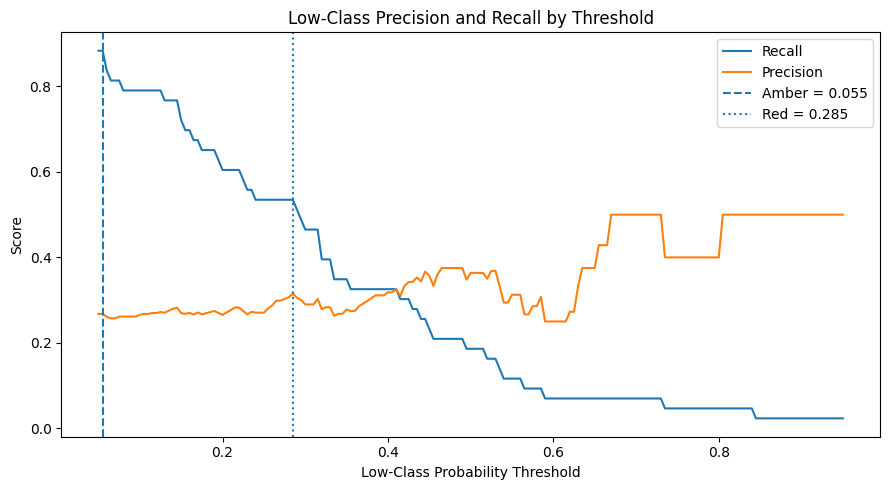

In [14]:
# 10. Recall and precision by threshold

fig, ax = plt.subplots(
    figsize=(
        9,
        5
    )
)

ax.plot(
    threshold_table[
        "Threshold"
    ],
    threshold_table[
        "Recall"
    ],
    label="Recall"
)

ax.plot(
    threshold_table[
        "Threshold"
    ],
    threshold_table[
        "Precision"
    ],
    label="Precision"
)

ax.axvline(
    AMBER_THRESHOLD,
    linestyle="--",
    label=(
        f"Amber = "
        f"{AMBER_THRESHOLD:.3f}"
    )
)

ax.axvline(
    RED_THRESHOLD,
    linestyle=":",
    label=(
        f"Red = "
        f"{RED_THRESHOLD:.3f}"
    )
)

ax.set_title(
    "Low-Class Precision and Recall by Threshold"
)

ax.set_xlabel(
    "Low-Class Probability Threshold"
)

ax.set_ylabel(
    "Score"
)

ax.legend()

plt.tight_layout()
plt.show()

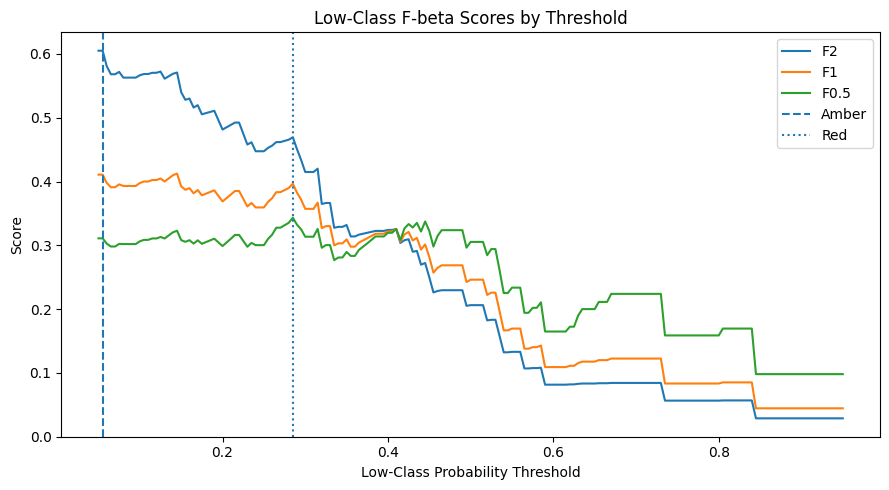

In [15]:
# 10.1 F-beta scores by threshold

fig, ax = plt.subplots(
    figsize=(
        9,
        5
    )
)

ax.plot(
    threshold_table[
        "Threshold"
    ],
    threshold_table[
        "F2"
    ],
    label="F2"
)

ax.plot(
    threshold_table[
        "Threshold"
    ],
    threshold_table[
        "F1"
    ],
    label="F1"
)

ax.plot(
    threshold_table[
        "Threshold"
    ],
    threshold_table[
        "F0.5"
    ],
    label="F0.5"
)

ax.axvline(
    AMBER_THRESHOLD,
    linestyle="--",
    label="Amber"
)

ax.axvline(
    RED_THRESHOLD,
    linestyle=":",
    label="Red"
)

ax.set_title(
    "Low-Class F-beta Scores by Threshold"
)

ax.set_xlabel(
    "Low-Class Probability Threshold"
)

ax.set_ylabel(
    "Score"
)

ax.legend()

plt.tight_layout()
plt.show()

## 11. Create OOF Early-Warning Bands

Candidate interpretation:

- **Green — Lower Risk:** Low-class probability below Amber threshold
- **Amber — Monitor:** probability at or above Amber but below Red
- **Red — Administrative Review:** probability at or above Red

`Red` does not mean automatic intervention or exclusion. It means the participant should receive priority human review.

In [16]:
# 11. Assign OOF risk bands

def assign_risk_band(
    low_probability,
    amber_threshold=AMBER_THRESHOLD,
    red_threshold=RED_THRESHOLD
):

    if pd.isna(
        low_probability
    ):

        return "Unknown"

    if (
        low_probability
        >= red_threshold
    ):

        return (
            "Red - Administrative Review"
        )

    if (
        low_probability
        >= amber_threshold
    ):

        return (
            "Amber - Monitor"
        )

    return (
        "Green - Lower Risk"
    )


selected_oof[
    "Risk Band"
] = (
    selected_oof[
        "Low Probability"
    ]
    .map(
        assign_risk_band
    )
)

display(
    selected_oof[
        [
            "Actual",
            "Predicted",
            "Low Probability",
            "Risk Band"
        ]
    ]
    .head()
)

,Actual,Predicted,Low Probability,Risk Band
346,High,Low,0.464808,Red - Administrative Review
347,High,High,0.319048,Red - Administrative Review
348,Moderate,Low,0.629324,Red - Administrative Review
349,Moderate,High,0.176847,Amber - Monitor
350,High,High,0.254622,Amber - Monitor


In [17]:
# 11.1 Risk-band distribution

risk_band_distribution = (
    selected_oof[
        "Risk Band"
    ]
    .value_counts()
    .rename_axis(
        "Risk Band"
    )
    .reset_index(
        name="Participants"
    )
)

risk_band_distribution[
    "Percentage"
] = (
    risk_band_distribution[
        "Participants"
    ]
    / risk_band_distribution[
        "Participants"
    ].sum()
    * 100
).round(2)

display(
    risk_band_distribution
)

,Risk Band,Participants,Percentage
0,Red - Administrative Review,73,42.20
1,Amber - Monitor,69,39.88
2,Green - Lower Risk,31,17.92


In [18]:
# 11.2 Actual trajectory within each risk band

risk_band_actual = pd.crosstab(
    selected_oof[
        "Risk Band"
    ],
    selected_oof[
        "Actual"
    ],
    margins=True
)

display(
    risk_band_actual
)

risk_band_actual_pct = pd.crosstab(
    selected_oof[
        "Risk Band"
    ],
    selected_oof[
        "Actual"
    ],
    normalize="index"
) * 100

display(
    risk_band_actual_pct.round(1)
)

Actual,High,Low,Moderate,All
Risk Band,,,,
Amber - Monitor,17,15,37,69
Green - Lower Risk,11,5,15,31
Red - Administrative Review,18,23,32,73
All,46,43,84,173


Actual,High,Low,Moderate
Risk Band,,,
Amber - Monitor,24.6,21.7,53.6
Green - Lower Risk,35.5,16.1,48.4
Red - Administrative Review,24.7,31.5,43.8


In [19]:
# 11.3 How many actual Low participants are captured?

low_capture = (
    selected_oof[
        selected_oof[
            "Actual"
        ].eq(
            "Low"
        )
    ][
        "Risk Band"
    ]
    .value_counts()
    .rename_axis(
        "Risk Band"
    )
    .reset_index(
        name="Actual Low Participants"
    )
)

low_capture[
    "% of All Actual Low"
] = (
    low_capture[
        "Actual Low Participants"
    ]
    / selected_oof[
        "Actual"
    ]
    .eq(
        "Low"
    )
    .sum()
    * 100
).round(1)

display(
    low_capture
)

,Risk Band,Actual Low Participants,% of All Actual Low
0,Red - Administrative Review,23,53.5
1,Amber - Monitor,15,34.9
2,Green - Lower Risk,5,11.6


# Explainable AI

## 12. Install and Import SHAP


In [20]:
# 12. Import SHAP

try:

    import shap

    print(
        "SHAP version:",
        shap.__version__
    )

except ImportError:

    !pip -q install shap

    import shap

    print(
        "SHAP installed:",
        shap.__version__
    )

SHAP version: 0.52.0


## 13. Transform the Final Dataset for SHAP

In [21]:
# 13. Transform modelling data

X_transformed = (
    final_pipeline
    .named_steps[
        "preprocess"
    ]
    .transform(
        X_full
    )
)

X_transformed = np.asarray(
    X_transformed
)

feature_names = (
    final_pipeline
    .named_steps[
        "preprocess"
    ]
    .get_feature_names_out()
)

print(
    "Transformed matrix:",
    X_transformed.shape
)

print(
    "Feature names:",
    len(
        feature_names
    )
)

Transformed matrix: (173, 35)
Feature names: 35


## 14. Create SHAP Explainer

For computational efficiency, the notebook uses a small representative background sample when necessary.

In [22]:
# 14. Create SHAP explainer

rng = np.random.default_rng(
    42
)

background_n = min(
    50,
    len(
        X_transformed
    )
)

background_indices = (
    rng.choice(
        len(
            X_transformed
        ),
        size=background_n,
        replace=False
    )
)

shap_background = (
    X_transformed[
        background_indices
    ]
)

final_estimator = (
    final_pipeline
    .named_steps[
        "model"
    ]
)

try:

    shap_explainer = shap.Explainer(
        final_estimator,
        shap_background,
        feature_names=feature_names
    )

    shap_values = shap_explainer(
        X_transformed
    )

except Exception as error:

    print(
        "Default SHAP explainer failed:"
    )

    print(
        error
    )

    print(
        "Trying model-specific explainer..."
    )

    if (
        selected_model_name
        == "Logistic Regression"
    ):

        shap_explainer = (
            shap.LinearExplainer(
                final_estimator,
                shap_background,
                feature_names=feature_names
            )
        )

        shap_values = (
            shap_explainer(
                X_transformed
            )
        )

    else:

        shap_explainer = (
            shap.TreeExplainer(
                final_estimator
            )
        )

        shap_values = (
            shap_explainer(
                X_transformed
            )
        )

print(
    "SHAP calculation complete."
)

Default SHAP explainer failed:
Categorical split is not yet supported. You can still use TreeExplainer with `feature_perturbation=tree_path_dependent`.
Trying model-specific explainer...
SHAP calculation complete.


## 15. Extract Low-Class SHAP Values

In [23]:
# 15. Extract SHAP values for the Low trajectory

def extract_low_shap(
    shap_output,
    low_code,
    n_classes
):

    if isinstance(
        shap_output,
        list
    ):

        return np.asarray(
            shap_output[
                low_code
            ]
        )

    values = np.asarray(
        shap_output.values
        if hasattr(
            shap_output,
            "values"
        )
        else shap_output
    )

    if (
        values.ndim
        == 2
    ):

        return values

    if (
        values.ndim
        == 3
    ):

        if (
            values.shape[
                -1
            ]
            == n_classes
        ):

            return values[
                :,
                :,
                low_code
            ]

        if (
            values.shape[
                0
            ]
            == n_classes
        ):

            return values[
                low_code,
                :,
                :
            ]

    raise ValueError(
        f"Unexpected SHAP shape: {values.shape}"
    )


low_shap_values = extract_low_shap(
    shap_values,
    LOW_CODE,
    len(
        CLASS_NAMES
    )
)

print(
    "Low-class SHAP shape:",
    low_shap_values.shape
)

Low-class SHAP shape: (173, 35)


## 16. Global Low-Risk Feature Importance

In [24]:
# 16. Global Low-class SHAP importance

global_low_importance = (
    pd.DataFrame({
        "Feature":
            feature_names,
        "Mean Absolute SHAP":
            np.abs(
                low_shap_values
            ).mean(
                axis=0
            )
    })
    .sort_values(
        "Mean Absolute SHAP",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

display(
    global_low_importance.head(
        20
    )
)

,Feature,Mean Absolute SHAP
0,numeric__Age,0.119419
1,numeric__Estimated Remaining Balance,0.099209
2,categorical__Industry/Business Sector_Beauty &...,0.065050
3,numeric__Household Income,0.060981
4,numeric__behavior_avg_deduct_per_session,0.058146
5,numeric__TT_followers_pre,0.054320
6,numeric__digital_platform_count,0.037482
7,numeric__IG_followers_pre,0.031934
8,numeric__overall_competency_change_z,0.030232
9,numeric__FB_followers_pre,0.027161


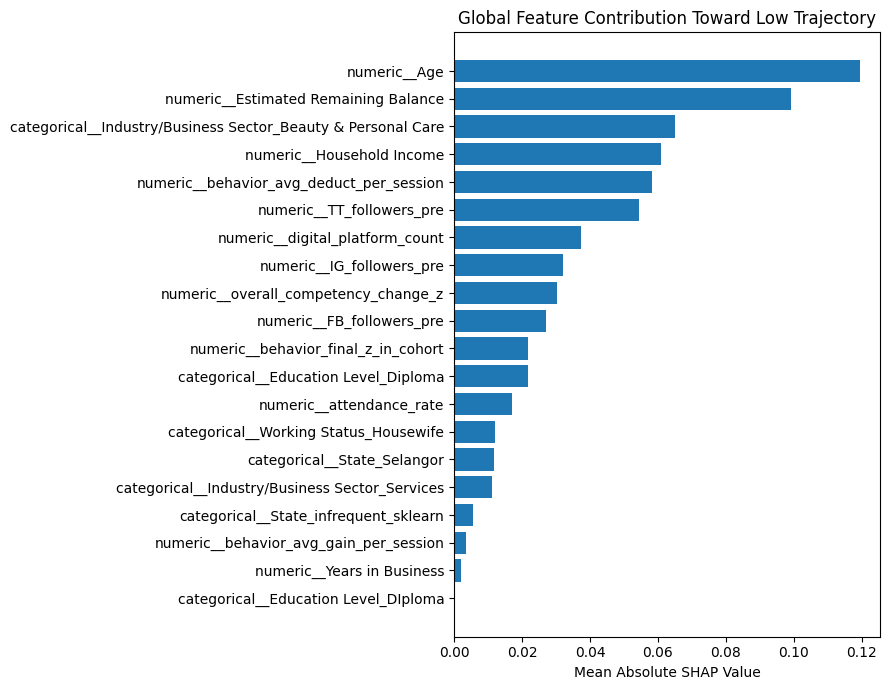

In [25]:
# 16.1 Plot top Low-class SHAP features

top_n = min(
    20,
    len(
        global_low_importance
    )
)

plot_data = (
    global_low_importance
    .head(
        top_n
    )
    .sort_values(
        "Mean Absolute SHAP",
        ascending=True
    )
)

fig, ax = plt.subplots(
    figsize=(
        9,
        7
    )
)

ax.barh(
    plot_data[
        "Feature"
    ],
    plot_data[
        "Mean Absolute SHAP"
    ]
)

ax.set_title(
    "Global Feature Contribution Toward Low Trajectory"
)

ax.set_xlabel(
    "Mean Absolute SHAP Value"
)

plt.tight_layout()
plt.show()

## 17. SHAP Direction Summary

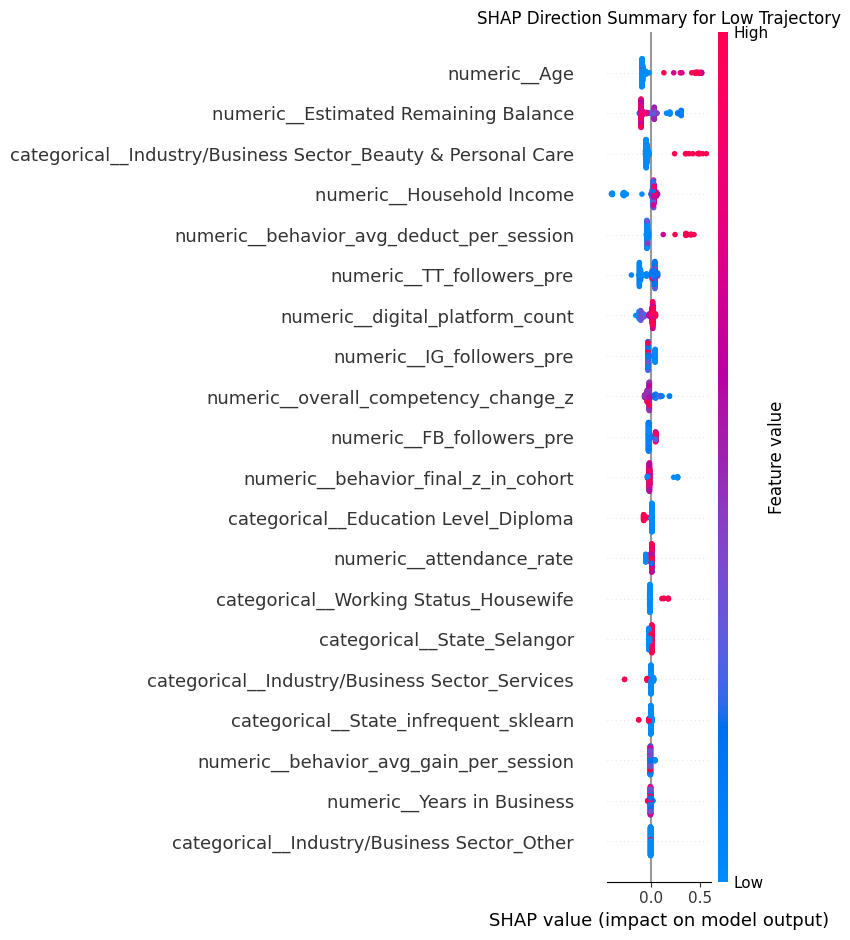

In [26]:
# 17. Directional Low-class SHAP summary

try:

    shap.summary_plot(
        low_shap_values,
        X_transformed,
        feature_names=feature_names,
        show=False
    )

    plt.title(
        "SHAP Direction Summary for Low Trajectory"
    )

    plt.tight_layout()
    plt.show()

except Exception as error:

    print(
        "SHAP summary plot could not be rendered:"
    )

    print(
        error
    )

# Local Early-Warning Explanation

## 18. Helper Functions for Human-Readable Feature Names

In [27]:
# 18. Clean transformed feature labels

def clean_feature_name(
    feature_name
):

    text = str(
        feature_name
    )

    text = text.replace(
        "numeric__",
        ""
    )

    text = text.replace(
        "categorical__",
        ""
    )

    text = text.replace(
        "_infrequent_sklearn",
        " = Other / Rare"
    )

    return text


def feature_group(
    feature_name
):

    text = (
        clean_feature_name(
            feature_name
        )
        .lower()
    )

    if any(
        keyword in text
        for keyword in [
            "attendance",
            "behavior"
        ]
    ):

        return (
            "Engagement / Behavior"
        )

    if any(
        keyword in text
        for keyword in [
            "digital",
            "followers",
            "instagram",
            "facebook",
            "tiktok",
            "ig_",
            "fb_",
            "tt_"
        ]
    ):

        return (
            "Digital Readiness"
        )

    if any(
        keyword in text
        for keyword in [
            "competency",
            "delta"
        ]
    ):

        return (
            "Competency"
        )

    if (
        "ssm"
        in text
    ):

        return (
            "Business Formalisation"
        )

    return (
        "Contextual / Baseline"
    )

## 19. Local Low-Risk Explanation Function

In [28]:
# 19. Get top SHAP contributors for one row

def local_low_explanation(
    row_index,
    top_n=8
):

    if (
        row_index
        < 0
        or row_index
        >= len(
            X_full
        )
    ):

        raise IndexError(
            "row_index is outside the modelling dataset."
        )

    contributions = pd.DataFrame({
        "Feature":
            feature_names,
        "Display Feature": [
            clean_feature_name(
                feature
            )
            for feature in feature_names
        ],
        "Feature Group": [
            feature_group(
                feature
            )
            for feature in feature_names
        ],
        "SHAP Toward Low":
            low_shap_values[
                row_index
            ]
    })

    contributions[
        "Absolute SHAP"
    ] = (
        contributions[
            "SHAP Toward Low"
        ]
        .abs()
    )

    contributions = (
        contributions
        .sort_values(
            "Absolute SHAP",
            ascending=False
        )
        .head(
            top_n
        )
    )

    return contributions

## 20. Demonstrate Local Explanation



In [29]:
# 20. Example participant for local explanation

example_oof = (
    selected_oof
    .sort_values(
        "Low Probability",
        ascending=False
    )
    .iloc[0]
)

example_index = int(
    example_oof[
        "Row Index"
    ]
)

print(
    "Research row index:",
    example_index
)

print(
    "Actual trajectory:",
    example_oof[
        "Actual"
    ]
)

print(
    "OOF Low probability:",
    round(
        example_oof[
            "Low Probability"
        ],
        3
    )
)

print(
    "OOF risk band:",
    example_oof[
        "Risk Band"
    ]
)

display(
    local_low_explanation(
        example_index,
        top_n=10
    )
)

Research row index: 163
Actual trajectory: Low
OOF Low probability: 0.963
OOF risk band: Red - Administrative Review


,Feature,Display Feature,Feature Group,SHAP Toward Low,Absolute SHAP
0,numeric__Age,Age,Contextual / Baseline,0.494903,0.494903
13,numeric__overall_competency_change_z,overall_competency_change_z,Competency,0.073354,0.073354
8,numeric__TT_followers_pre,TT_followers_pre,Digital Readiness,-0.040687,0.040687
28,categorical__Industry/Business Sector_Beauty &...,Industry/Business Sector_Beauty & Personal Care,Contextual / Baseline,-0.035297,0.035297
3,numeric__Estimated Remaining Balance,Estimated Remaining Balance,Contextual / Baseline,0.033855,0.033855
2,numeric__Household Income,Household Income,Contextual / Baseline,0.033431,0.033431
33,categorical__Industry/Business Sector_Services,Industry/Business Sector_Services,Contextual / Baseline,0.028659,0.028659
6,numeric__IG_followers_pre,IG_followers_pre,Digital Readiness,-0.026343,0.026343
11,numeric__behavior_avg_deduct_per_session,behavior_avg_deduct_per_session,Engagement / Behavior,-0.022973,0.022973
7,numeric__FB_followers_pre,FB_followers_pre,Digital Readiness,-0.020598,0.020598


# Administrative Intervention Logic

## 21. Actionable Review Mapping


In [30]:
# 21. Administrative review mapping

INTERVENTION_MAPPING = {
    "Engagement / Behavior": {
        "review": (
            "Review attendance, participation and trainer observations."
        ),
        "support": (
            "Consider a trainer or mentor check-in and targeted engagement support."
        )
    },

    "Digital Readiness": {
        "review": (
            "Review baseline digital adoption and digital business activity."
        ),
        "support": (
            "Consider digital marketing, content, platform or e-commerce coaching."
        )
    },

    "Competency": {
        "review": (
            "Review competency assessment results and areas with limited improvement."
        ),
        "support": (
            "Consider targeted refresher training or one-to-one competency coaching."
        )
    },

    "Business Formalisation": {
        "review": (
            "Review business formalisation readiness."
        ),
        "support": (
            "Consider guidance on registration, records and formal business processes."
        )
    }
}

display(
    pd.DataFrame(
        [
            {
                "Feature Group":
                    group,
                **content
            }
            for group, content
            in INTERVENTION_MAPPING.items()
        ]
    )
)

,Feature Group,review,support
0,Engagement / Behavior,"Review attendance, participation and trainer o...",Consider a trainer or mentor check-in and targ...
1,Digital Readiness,Review baseline digital adoption and digital b...,"Consider digital marketing, content, platform ..."
2,Competency,Review competency assessment results and areas...,Consider targeted refresher training or one-to...
3,Business Formalisation,Review business formalisation readiness.,"Consider guidance on registration, records and..."


In [31]:
# 21.1 Build recommendations from positive Low-risk contributors

def build_recommendations(
    explanation_df,
    max_recommendations=3
):

    positive = (
        explanation_df[
            explanation_df[
                "SHAP Toward Low"
            ]
            > 0
        ]
        .copy()
    )

    positive = (
        positive[
            positive[
                "Feature Group"
            ]
            .isin(
                INTERVENTION_MAPPING.keys()
            )
        ]
    )

    recommendations = []

    used_groups = set()

    for _, row in (
        positive
        .sort_values(
            "Absolute SHAP",
            ascending=False
        )
        .iterrows()
    ):

        group = row[
            "Feature Group"
        ]

        if (
            group
            in used_groups
        ):

            continue

        recommendations.append({
            "Feature Group":
                group,
            "Review":
                INTERVENTION_MAPPING[
                    group
                ][
                    "review"
                ],
            "Suggested Support":
                INTERVENTION_MAPPING[
                    group
                ][
                    "support"
                ]
        })

        used_groups.add(
            group
        )

        if (
            len(
                recommendations
            )
            >= max_recommendations
        ):

            break

    return pd.DataFrame(
        recommendations
    )


example_explanation = (
    local_low_explanation(
        example_index,
        top_n=15
    )
)

display(
    build_recommendations(
        example_explanation
    )
)

,Feature Group,Review,Suggested Support
0,Competency,Review competency assessment results and areas...,Consider targeted refresher training or one-to...
1,Digital Readiness,Review baseline digital adoption and digital b...,"Consider digital marketing, content, platform ..."
2,Engagement / Behavior,"Review attendance, participation and trainer o...",Consider a trainer or mentor check-in and targ...


# Prototype Prediction Function

## 22. Early-Warning Inference Function


In [32]:
# 22. Predict trajectory and risk band

def predict_early_warning(
    raw_input
):

    if isinstance(
        raw_input,
        dict
    ):

        input_df = pd.DataFrame(
            [
                raw_input
            ]
        )

    elif isinstance(
        raw_input,
        pd.DataFrame
    ):

        input_df = (
            raw_input.copy()
        )

    else:

        raise TypeError(
            "Input must be a dictionary or pandas DataFrame."
        )

    missing_features = [
        feature
        for feature in X_full.columns
        if feature
        not in input_df.columns
    ]

    if missing_features:

        raise ValueError(
            "Missing model inputs: "
            + ", ".join(
                missing_features
            )
        )

    input_df = input_df[
        X_full.columns
    ]

    probabilities = (
        final_pipeline
        .predict_proba(
            input_df
        )
    )

    prediction_codes = (
        final_pipeline
        .predict(
            input_df
        )
    )

    prediction_labels = (
        label_encoder
        .inverse_transform(
            prediction_codes
            .astype(int)
        )
    )

    probability_rows = []

    for row_number in range(
        len(
            input_df
        )
    ):

        class_probabilities = {
            CLASS_NAMES[
                class_index
            ]:
                float(
                    probabilities[
                        row_number,
                        class_index
                    ]
                )
            for class_index
            in range(
                len(
                    CLASS_NAMES
                )
            )
        }

        low_prob = (
            class_probabilities[
                "Low"
            ]
        )

        risk_band = (
            assign_risk_band(
                low_prob
            )
        )

        probability_rows.append({
            "Predicted Trajectory":
                prediction_labels[
                    row_number
                ],
            "Probability High":
                class_probabilities.get(
                    "High",
                    np.nan
                ),
            "Probability Moderate":
                class_probabilities.get(
                    "Moderate",
                    np.nan
                ),
            "Probability Low":
                low_prob,
            "Risk Band":
                risk_band,
            "Administrative Action":
                (
                    "Human review required"
                    if risk_band.startswith(
                        "Red"
                    )
                    else
                    (
                        "Monitor and review"
                        if risk_band.startswith(
                            "Amber"
                        )
                        else
                        "Routine monitoring"
                    )
                )
        })

    return pd.DataFrame(
        probability_rows
    )

In [33]:
# 22.1 Smoke test using one anonymous modelling row

test_input = (
    X_full
    .iloc[
        [
            0
        ]
    ]
    .copy()
)

display(
    predict_early_warning(
        test_input
    )
)

print(
    "This is a deployment-function test only."
)

,Predicted Trajectory,Probability High,Probability Moderate,Probability Low,Risk Band,Administrative Action
0,High,0.472408,0.25723,0.270362,Amber - Monitor,Monitor and review


This is a deployment-function test only.


# Hugging Face Deployment Preparation

## 23. Build Raw Input Schema


In [34]:
# 23. Build input schema for Gradio

input_schema = {}

for column in X_full.columns:

    if (
        column
        in numeric_features
    ):

        values = pd.to_numeric(
            X_full[
                column
            ],
            errors="coerce"
        )

        observed = (
            values
            .dropna()
        )

        if len(
            observed
        ) == 0:

            input_schema[
                column
            ] = {
                "type":
                    "number",
                "default":
                    None,
                "min":
                    None,
                "max":
                    None
            }

        else:

            median = float(
                observed.median()
            )

            minimum = float(
                observed.min()
            )

            maximum = float(
                observed.max()
            )

            input_schema[
                column
            ] = {
                "type":
                    "number",
                "default":
                    median,
                "min":
                    minimum,
                "max":
                    maximum
            }

    else:

        values = (
            X_full[
                column
            ]
            .dropna()
            .astype(str)
        )

        choices = sorted(
            values.unique().tolist()
        )

        default = (
            values.mode().iloc[0]
            if len(
                values
            )
            else None
        )

        input_schema[
            column
        ] = {
            "type":
                "categorical",
            "default":
                default,
            "choices":
                choices
        }

print(
    "Input controls:",
    len(
        input_schema
    )
)

display(
    pd.DataFrame(
        [
            {
                "Feature":
                    feature,
                "Type":
                    settings[
                        "type"
                    ],
                "Default":
                    settings.get(
                        "default"
                    )
            }
            for feature, settings
            in input_schema.items()
        ]
    )
)

Input controls: 18


,Feature,Type,Default
0,Age,number,26.0
1,State,categorical,Selangor
2,Education Level,categorical,SPM
3,Working Status,categorical,Self-Employed
4,Industry/Business Sector,categorical,Food & Beverage
5,Years in Business,number,5.0
6,Household Income,number,2200.0
7,Estimated Remaining Balance,number,-391.0
8,ssm_registered_binary,number,1.0
9,digital_platform_count,number,3.0


## 24. Deployment Configuration

In [35]:
# 24. Deployment configuration

risk_thresholds = {
    "method": {
        "amber": (
            "OOF Low probability threshold maximising F2"
        ),
        "red": (
            "Higher OOF Low probability threshold maximising F0.5"
        )
    },
    "amber_threshold":
        AMBER_THRESHOLD,
    "red_threshold":
        RED_THRESHOLD,
    "risk_bands": {
        "green":
            "Lower Risk",
        "amber":
            "Monitor",
        "red":
            "Administrative Review"
    }
}

deployment_config = {
    "project": (
        "Ibupreneur Early-Warning Framework"
    ),
    "selected_model":
        selected_model_name,
    "target":
        TARGET_COLUMN,
    "class_names":
        CLASS_NAMES,
    "low_class":
        "Low",
    "raw_predictor_count":
        int(
            X_full.shape[1]
        ),
    "transformed_feature_count":
        int(
            len(
                transformed_feature_names
            )
        ),
    "human_review_required":
        True,
    "automatic_eligibility_decision":
        False,
    "interface_target":
        "Hugging Face Spaces / Gradio"
}

print(
    json.dumps(
        deployment_config,
        indent=2
    )
)

{
  "project": "Ibupreneur Early-Warning Framework",
  "selected_model": "XGBoost",
  "target": "Performance Trajectory",
  "class_names": [
    "High",
    "Low",
    "Moderate"
  ],
  "low_class": "Low",
  "raw_predictor_count": 18,
  "transformed_feature_count": 35,
  "human_review_required": true,
  "automatic_eligibility_decision": false,
  "interface_target": "Hugging Face Spaces / Gradio"
}


## 25. Save Deployment Model and Supporting Files

In [36]:
# 25. Save final deployment files

PIPELINE_PATH = (
    DEPLOYMENT_DIR
    / "final_early_warning_pipeline.joblib"
)

LABEL_ENCODER_PATH = (
    DEPLOYMENT_DIR
    / "label_encoder.joblib"
)

THRESHOLDS_PATH = (
    DEPLOYMENT_DIR
    / "risk_thresholds.json"
)

CONFIG_PATH = (
    DEPLOYMENT_DIR
    / "deployment_config.json"
)

INPUT_SCHEMA_PATH = (
    DEPLOYMENT_DIR
    / "input_schema.json"
)

INTERVENTION_PATH = (
    DEPLOYMENT_DIR
    / "intervention_mapping.json"
)

SHAP_BACKGROUND_PATH = (
    DEPLOYMENT_DIR
    / "shap_background.npy"
)

GLOBAL_SHAP_PATH = (
    DEPLOYMENT_DIR
    / "global_low_shap_importance.csv"
)

THRESHOLD_AUDIT_PATH = (
    DEPLOYMENT_DIR
    / "threshold_performance_audit.csv"
)

RISK_BAND_AUDIT_PATH = (
    DEPLOYMENT_DIR
    / "oof_early_warning_audit.csv"
)

SELECTION_REVIEW_PATH = (
    DEPLOYMENT_DIR
    / "final_model_selection_review.csv"
)

RAW_FEATURES_PATH = (
    DEPLOYMENT_DIR
    / "raw_model_features.json"
)


joblib.dump(
    final_pipeline,
    PIPELINE_PATH
)

joblib.dump(
    label_encoder,
    LABEL_ENCODER_PATH
)


with open(
    THRESHOLDS_PATH,
    "w"
) as file:

    json.dump(
        risk_thresholds,
        file,
        indent=2
    )


with open(
    CONFIG_PATH,
    "w"
) as file:

    json.dump(
        deployment_config,
        file,
        indent=2
    )


with open(
    INPUT_SCHEMA_PATH,
    "w"
) as file:

    json.dump(
        input_schema,
        file,
        indent=2
    )


with open(
    INTERVENTION_PATH,
    "w"
) as file:

    json.dump(
        INTERVENTION_MAPPING,
        file,
        indent=2
    )


with open(
    RAW_FEATURES_PATH,
    "w"
) as file:

    json.dump(
        list(
            X_full.columns
        ),
        file,
        indent=2
    )


np.save(
    SHAP_BACKGROUND_PATH,
    shap_background
)


global_low_importance.to_csv(
    GLOBAL_SHAP_PATH,
    index=False
)


threshold_table.to_csv(
    THRESHOLD_AUDIT_PATH,
    index=False
)


selected_oof.to_csv(
    RISK_BAND_AUDIT_PATH,
    index=False
)


selection_review.to_csv(
    SELECTION_REVIEW_PATH,
    index=False
)


print(
    "Deployment files saved to:"
)

print(
    DEPLOYMENT_DIR
)

Deployment files saved to:
/content/drive/MyDrive/24088950_MAI_Research/outputs/deployment


## 26. Create Deployment README

In [37]:
# 26. Create deployment README

deployment_readme = f"""
# Ibupreneur Early-Warning Deployment Package

Selected model: {selected_model_name}

Primary target:
- High
- Moderate
- Low

Early-warning signal:
- Low-class probability

Candidate risk thresholds:
- Amber: {AMBER_THRESHOLD:.3f}
- Red: {RED_THRESHOLD:.3f}

Risk interpretation:
- Green: routine monitoring
- Amber: monitor and review
- Red: priority administrative review

Important:
This prototype is a decision-support system.
It must not automatically determine programme eligibility,
funding, graduation, or withdrawal of support.

Files:
- final_early_warning_pipeline.joblib
- label_encoder.joblib
- risk_thresholds.json
- deployment_config.json
- input_schema.json
- intervention_mapping.json
- raw_model_features.json
- shap_background.npy
- global_low_shap_importance.csv
- threshold_performance_audit.csv
- oof_early_warning_audit.csv
- final_model_selection_review.csv

Next:
Use Notebook 07 to generate a Gradio app for Hugging Face Spaces.
""".strip()

README_PATH = (
    DEPLOYMENT_DIR
    / "README_DEPLOYMENT.md"
)

README_PATH.write_text(
    deployment_readme,
    encoding="utf-8"
)

print(
    deployment_readme
)

# Ibupreneur Early-Warning Deployment Package

Selected model: XGBoost

Primary target:
- High
- Moderate
- Low

Early-warning signal:
- Low-class probability

Candidate risk thresholds:
- Amber: 0.055
- Red: 0.285

Risk interpretation:
- Green: routine monitoring
- Amber: monitor and review
- Red: priority administrative review

Important:
This prototype is a decision-support system.
It must not automatically determine programme eligibility,
funding, graduation, or withdrawal of support.

Files:
- final_early_warning_pipeline.joblib
- label_encoder.joblib
- risk_thresholds.json
- deployment_config.json
- input_schema.json
- intervention_mapping.json
- raw_model_features.json
- shap_background.npy
- global_low_shap_importance.csv
- threshold_performance_audit.csv
- oof_early_warning_audit.csv
- final_model_selection_review.csv

Next:
Use Notebook 07 to generate a Gradio app for Hugging Face Spaces.


## 27. Create Deployment ZIP



In [38]:
# 27. Zip deployment package

zip_base = (
    OUTPUT_DIR
    / "ibupreneur_early_warning_deployment"
)

zip_path = shutil.make_archive(
    str(
        zip_base
    ),
    "zip",
    root_dir=(
        DEPLOYMENT_DIR
    )
)

print(
    "Deployment ZIP:",
    zip_path
)

Deployment ZIP: /content/drive/MyDrive/24088950_MAI_Research/outputs/ibupreneur_early_warning_deployment.zip


# Final Validation

## 28. Deployment File Audit

In [39]:
# 28. Check deployment files

deployment_files = []

for path in sorted(
    DEPLOYMENT_DIR.iterdir()
):

    if path.is_file():

        deployment_files.append({
            "File":
                path.name,
            "Size KB":
                round(
                    path.stat().st_size
                    / 1024,
                    2
                )
        })

deployment_file_audit = pd.DataFrame(
    deployment_files
)

display(
    deployment_file_audit
)

,File,Size KB
0,README_DEPLOYMENT.md,0.89
1,deployment_config.json,0.39
2,final_early_warning_pipeline.joblib,276.02
3,final_model_selection_review.csv,0.69
4,global_low_shap_importance.csv,1.57
5,input_schema.json,2.72
6,intervention_mapping.json,0.77
7,label_encoder.joblib,0.49
8,oof_early_warning_audit.csv,21.02
9,raw_model_features.json,0.44


## 29. Final Early-Warning Summary


In [40]:
# 29. Final summary



print()

print(
    "Selected model:",
    selected_model_name
)

selected_row = (
    selection_review[
        selection_review[
            "Model"
        ].eq(
            selected_model_name
        )
    ]
    .iloc[0]
)

print(
    "Nested-CV Macro-F1:",
    round(
        selected_row[
            "Macro F1"
        ],
        3
    )
)

print(
    "OOF Low Recall:",
    round(
        selected_row[
            "Low Recall"
        ],
        3
    )
)

print(
    "Amber threshold:",
    AMBER_THRESHOLD
)

print(
    "Red threshold:",
    RED_THRESHOLD
)

print(
    "Raw predictors:",
    X_full.shape[1]
)

print(
    "Transformed predictors:",
    len(
        transformed_feature_names
    )
)

print()

print(
    "Deployment folder:",
    DEPLOYMENT_DIR
)






Selected model: XGBoost
Nested-CV Macro-F1: 0.403
OOF Low Recall: 0.326
Amber threshold: 0.055
Red threshold: 0.285
Raw predictors: 18
Transformed predictors: 35

Deployment folder: /content/drive/MyDrive/24088950_MAI_Research/outputs/deployment
